In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("/content/googleplaystore.csv")

df.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [3]:
print("Dataset Shape:", df.shape)

df.info()

df.describe()

print(df.isnull().sum())

Dataset Shape: (10841, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB
App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             

In [4]:
df = df.drop_duplicates(subset="App", keep="last")

In [5]:
df["Rating"] = df["Rating"].fillna(df["Rating"].median())

df["Type"] = df["Type"].fillna(df["Type"].mode()[0])

df["Content Rating"] = df["Content Rating"].fillna(
    df["Content Rating"].mode()[0]
)

In [6]:
df["Reviews"] = pd.to_numeric(df["Reviews"], errors="coerce")

In [7]:
df["Installs"] = (
    df["Installs"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.replace("+", "", regex=False)
)

df["Installs"] = pd.to_numeric(df["Installs"], errors="coerce")

In [8]:
df["Price"] = (
    df["Price"]
    .astype(str)
    .str.replace("$", "", regex=False)
)

df["Price"] = pd.to_numeric(df["Price"], errors="coerce")

In [9]:
df = df.dropna(subset=["App", "Category", "Rating", "Reviews", "Installs"])

df = df[df["Rating"].between(0, 5)]

df = df[df["Price"] >= 0]

df.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159.0,19M,10000.0,Free,0.0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510.0,8.7M,5000000.0,Free,0.0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644.0,25M,50000000.0,Free,0.0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967.0,2.8M,100000.0,Free,0.0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up
5,Paper flowers instructions,ART_AND_DESIGN,4.4,167.0,5.6M,50000.0,Free,0.0,Everyone,Art & Design,"March 26, 2017",1.0,2.3 and up


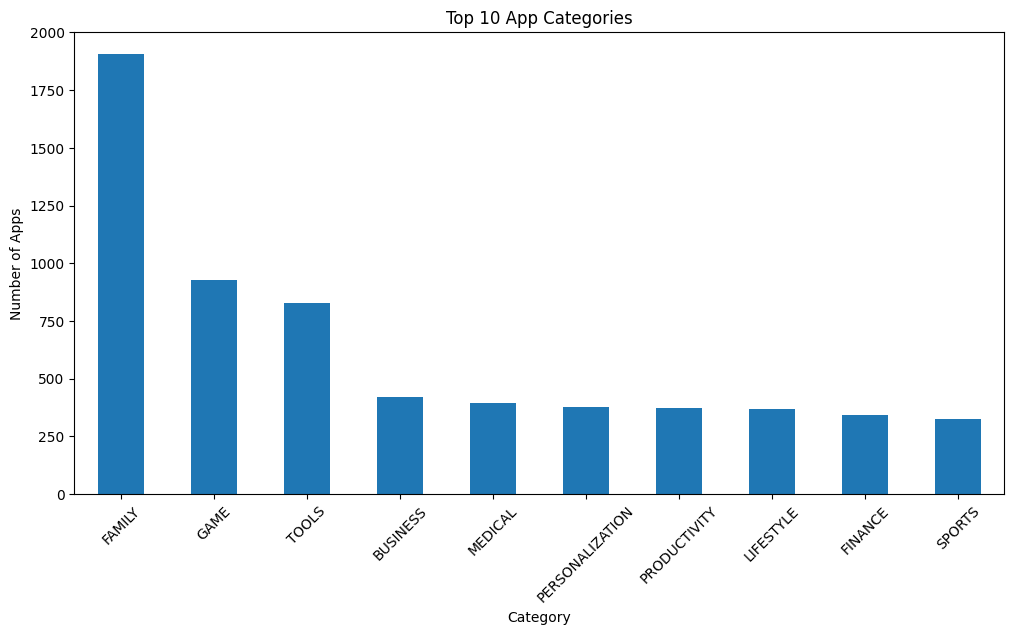

In [10]:
plt.figure(figsize=(12,6))

df["Category"].value_counts().head(10).plot(kind="bar")

plt.title("Top 10 App Categories")
plt.xlabel("Category")
plt.ylabel("Number of Apps")

plt.xticks(rotation=45)
plt.show()

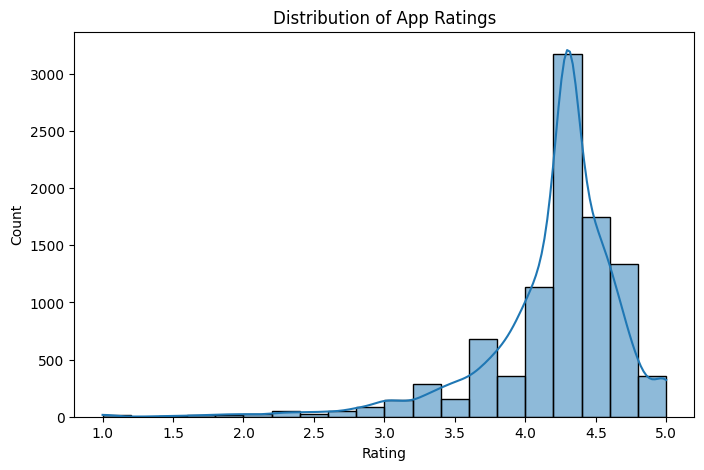

In [11]:
plt.figure(figsize=(8,5))

sns.histplot(df["Rating"], bins=20, kde=True)

plt.title("Distribution of App Ratings")
plt.xlabel("Rating")

plt.show()

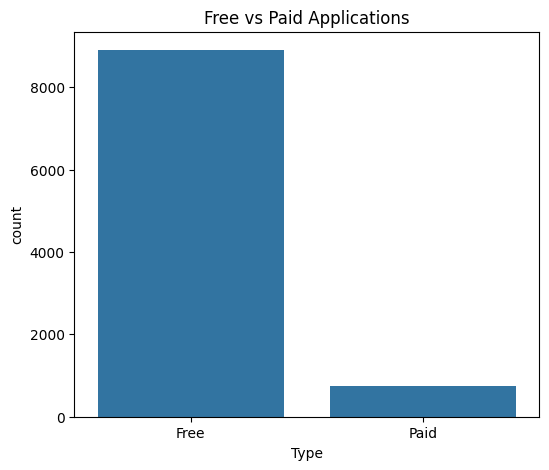

In [12]:
plt.figure(figsize=(6,5))

sns.countplot(x="Type", data=df)

plt.title("Free vs Paid Applications")

plt.show()

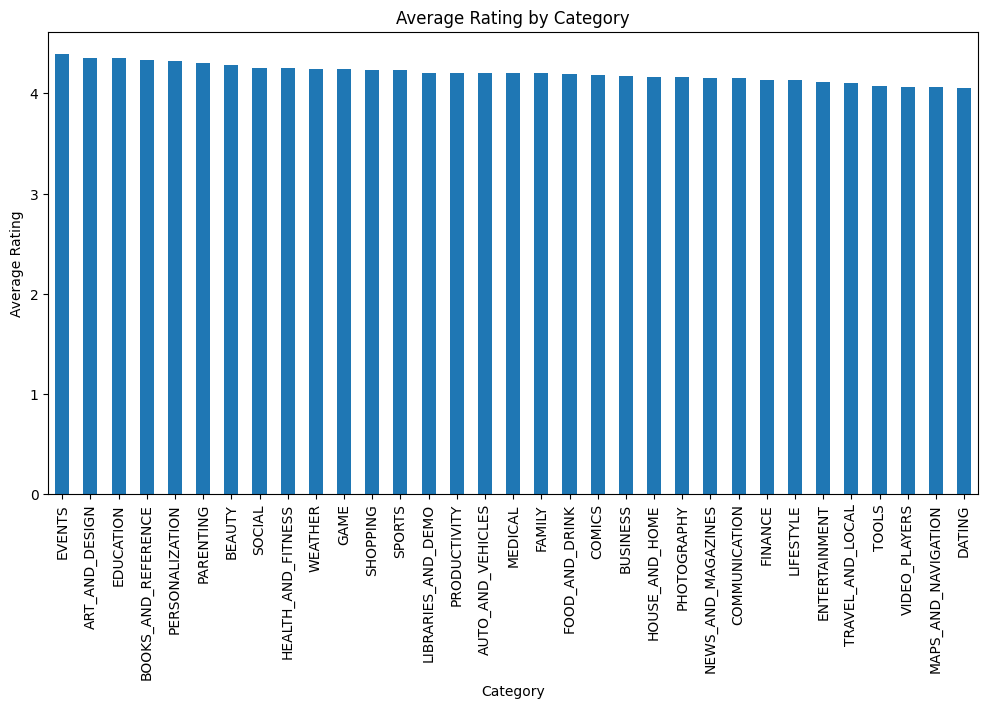

In [13]:
category_rating = df.groupby("Category")["Rating"].mean().sort_values(
    ascending=False
)

plt.figure(figsize=(12,6))

category_rating.plot(kind="bar")

plt.title("Average Rating by Category")
plt.ylabel("Average Rating")

plt.xticks(rotation=90)
plt.show()

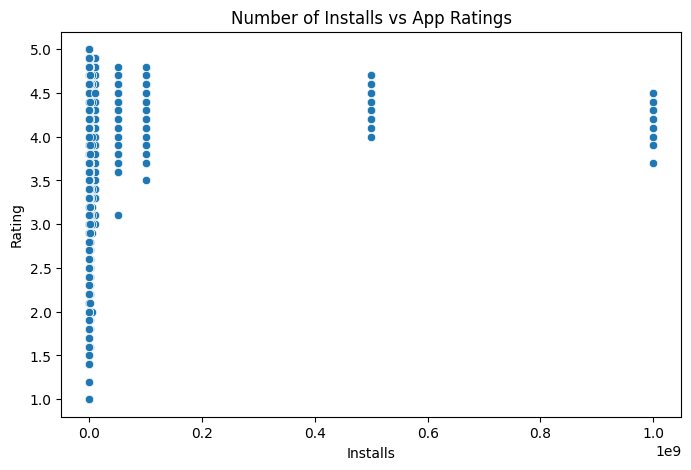

In [14]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    x="Installs",
    y="Rating",
    data=df
)

plt.title("Number of Installs vs App Ratings")

plt.show()

In [15]:
top_apps = df.sort_values(
    by="Installs",
    ascending=False
).head(10)

print(top_apps[["App", "Category", "Installs", "Rating"]])

                                           App             Category  \
3943                                  Facebook               SOCIAL   
3996              Google Chrome: Fast & Secure        COMMUNICATION   
3928                                   YouTube        VIDEO_PLAYERS   
152                          Google Play Books  BOOKS_AND_REFERENCE   
9844                               Google News   NEWS_AND_MAGAZINES   
4098                 Maps - Navigate & Explore     TRAVEL_AND_LOCAL   
4096                                     Gmail        COMMUNICATION   
3909                                 Instagram               SOCIAL   
4104  Messenger – Text and Video Chat for Free        COMMUNICATION   
3687                   Google Play Movies & TV        VIDEO_PLAYERS   

          Installs  Rating  
3943  1.000000e+09     4.1  
3996  1.000000e+09     4.3  
3928  1.000000e+09     4.3  
152   1.000000e+09     3.9  
9844  1.000000e+09     3.9  
4098  1.000000e+09     4.3  
4096  1.000000e

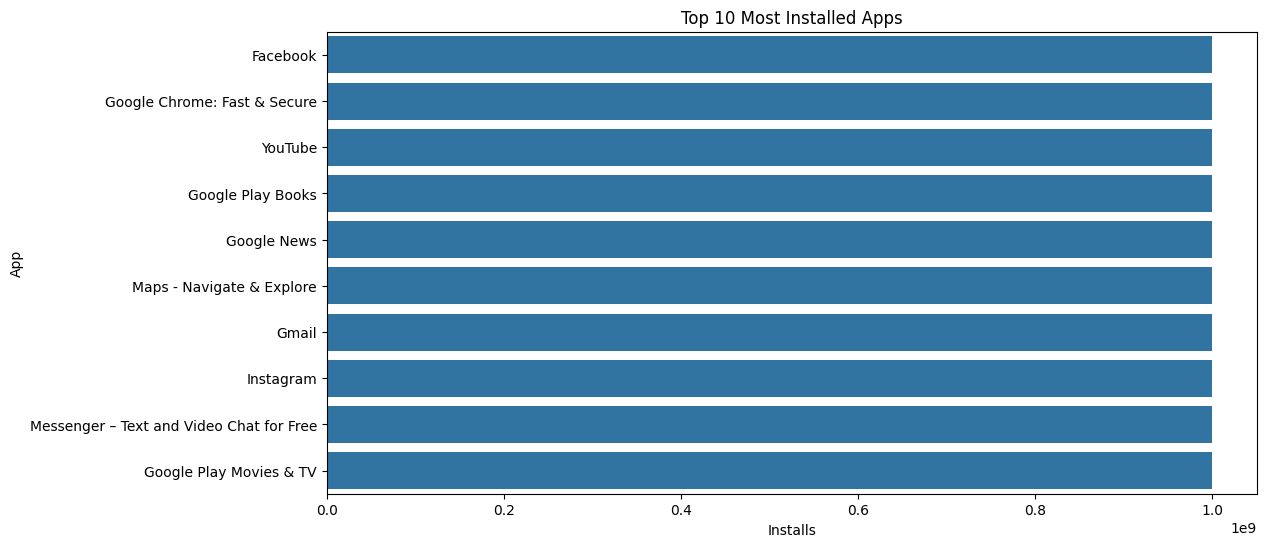

In [16]:
plt.figure(figsize=(12,6))

sns.barplot(
    x="Installs",
    y="App",
    data=top_apps
)

plt.title("Top 10 Most Installed Apps")

plt.show()

In [17]:
paid_apps = df[df["Price"] > 0]

expensive_apps = paid_apps.sort_values(
    by="Price",
    ascending=False
).head(10)

print(expensive_apps[["App", "Price", "Rating"]])

                                    App   Price  Rating
4367           I'm Rich - Trump Edition  400.00     3.6
9934  I'm Rich/Eu sou Rico/أنا غني/我很有錢  399.99     4.3
4197             most expensive app (H)  399.99     4.3
4362                         💎 I'm rich  399.99     3.8
5356                  I Am Rich Premium  399.99     4.1
5373                 I AM RICH PRO PLUS  399.99     4.0
5351                          I am rich  399.99     3.8
5354                     I am Rich Plus  399.99     4.0
5369                          I am Rich  399.99     4.3
5359                 I am rich(premium)  399.99     3.5


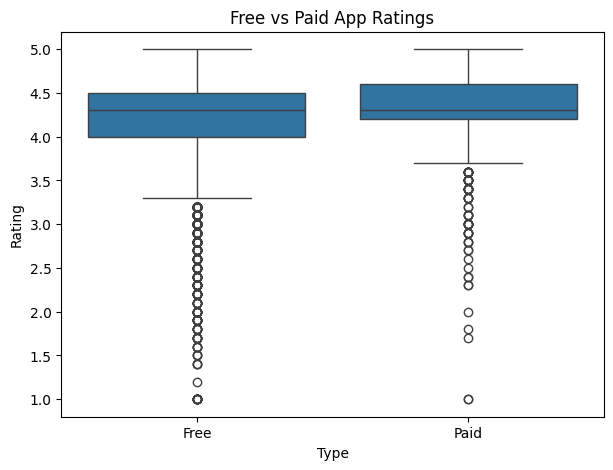

In [18]:
plt.figure(figsize=(7,5))

sns.boxplot(
    x="Type",
    y="Rating",
    data=df
)

plt.title("Free vs Paid App Ratings")

plt.show()

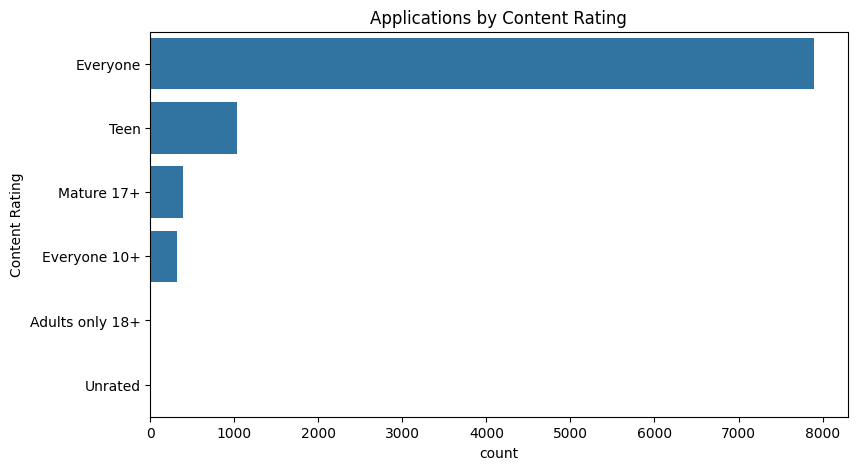

In [19]:
plt.figure(figsize=(9,5))

sns.countplot(
    y="Content Rating",
    data=df,
    order=df["Content Rating"].value_counts().index
)

plt.title("Applications by Content Rating")

plt.show()

In [20]:
top_reviewed = df.sort_values(
    by="Reviews",
    ascending=False
).head(10)

print(top_reviewed[["App", "Reviews", "Rating"]])

                                                    App     Reviews  Rating
3943                                           Facebook  78128208.0     4.1
3904                                 WhatsApp Messenger  69109672.0     4.4
3909                                          Instagram  66509917.0     4.5
4104           Messenger – Text and Video Chat for Free  56642847.0     4.0
3986                                     Clash of Clans  44881447.0     4.6
4005            Clean Master- Space Cleaner & Antivirus  42916526.0     4.7
3896                                     Subway Surfers  27711703.0     4.5
3928                                            YouTube  25623548.0     4.3
7536  Security Master - Antivirus, VPN, AppLock, Boo...  24900999.0     4.7
3987                                       Clash Royale  23125280.0     4.6


In [21]:
category_summary = df.groupby("Category").agg({
    "App": "count",
    "Rating": "mean",
    "Reviews": "mean",
    "Installs": "mean",
    "Price": "mean"
}).rename(columns={"App": "Number_of_Apps"})

category_summary = category_summary.sort_values(
    by="Installs",
    ascending=False
)

category_summary.head(10)

,Number_of_Apps,Rating,Reviews,Installs,Price
Category,,,,,
COMMUNICATION,316,4.154747,904508.914557,3.493442e+07,0.263101
VIDEO_PLAYERS,163,4.066871,413035.607362,2.403069e+07,0.064172
SOCIAL,239,4.255230,953147.962343,2.296179e+07,0.066820
PHOTOGRAPHY,281,4.165125,375646.992883,1.657704e+07,0.420925
PRODUCTIVITY,374,4.206150,148583.812834,1.547618e+07,0.670936
TRAVEL_AND_LOCAL,219,4.103196,122452.205479,1.321866e+07,0.228082
GAME,926,4.243305,459221.650108,1.176882e+07,0.307030
TOOLS,829,4.074427,276759.624849,9.774152e+06,0.322376
NEWS_AND_MAGAZINES,254,4.156693,91027.149606,9.327629e+06,0.015669


In [22]:
df.to_csv("cleaned_googleplaystore.csv", index=False)